In [1]:
from pathlib import Path
import os

REPO = Path.cwd()
while not (REPO / "pyproject.toml").exists() and REPO != REPO.parent:
    REPO = REPO.parent
os.chdir(REPO)      # all paths below are relative to the repository root

import json
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from ct_iqa.config.loader import load_study_config
from ct_iqa.config.schema import ModelConfig
from ct_iqa.data.ldct_iqac import LDCTIQACDataset, LDCTIQACLabelError
from ct_iqa.models.registry import build_model
from ct_iqa.preprocessing.crop import CropSizeError, center_crop
from ct_iqa.preprocessing.normalize import to_radimagenet_range
from ct_iqa.preprocessing.transforms import preprocess_ct_image


def show(title, obj):
    """Print a section title, then the table as plain text (no interactive viewer)."""
    print(f"\n=== {title} ===")
    print(obj.to_string())

RESULTS = {}     # test name -> bool, summarized in the final cell


def expect(name, condition):
    RESULTS[name] = bool(condition)


def raises(exc, fn, *args):
    try:
        fn(*args)
    except exc:
        return True
    except Exception:
        return False
    return False


=== Value range before and after (the crop removes the ramp ends, so the range is NOT -1..1) ===
                        min     max
input, whole image   0.0000  1.0000
after crop and 2x-1 -0.4364  0.4364


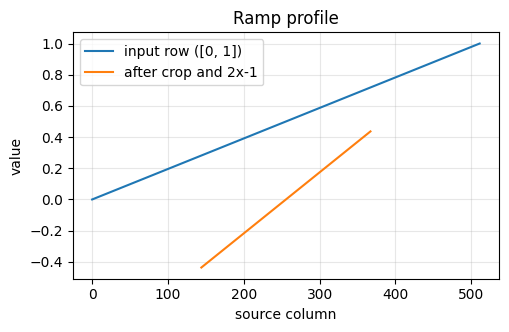

In [2]:
x = np.tile(np.linspace(0, 1, 512, dtype=np.float32), (512, 1))
y = preprocess_ct_image(x, 224)
expect("ramp: output shape is 224x224", y.shape == (224, 224))
expect("ramp: output dtype is float32", y.dtype == np.float32)
expect("ramp: crop is columns 144..367", np.array_equal(y, 2 * x[144:368, 144:368] - 1))
expect("ramp: output equals 2*crop-1 exactly", np.array_equal(y, to_radimagenet_range(center_crop(x, 224))))
show("Value range before and after (the crop removes the ramp ends, so the range is NOT -1..1)", pd.DataFrame(
    {"min": [x.min(), y.min()], "max": [x.max(), y.max()]}, index=["input, whole image", "after crop and 2x-1"]).round(4))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(x[0], label="input row ([0, 1])")
ax.plot(np.arange(144, 368), y[0], label="after crop and 2x-1")
ax.set(xlabel="source column", ylabel="value", title="Ramp profile"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [3]:
def coded(h, w):
    """Image whose pixel value encodes its own (row, col), so crop position can be checked exactly."""
    return (np.arange(h)[:, None] * 1000 + np.arange(w)[None, :]).astype(np.float64)


cases = {"512x512": (512, 512), "513x513 (odd excess)": (513, 513), "512x400 (rectangular)": (512, 400),
         "300x600 (rectangular)": (300, 600), "224x224 (exact size)": (224, 224), "225x224": (225, 224)}
rows = []
for label, (h, w) in cases.items():
    a = coded(h, w)
    c = center_crop(a, 224)
    top, left = (h - 224) // 2, (w - 224) // 2
    ok = c.shape == (224, 224) and np.array_equal(c, a[top:top + 224, left:left + 224]) and c[0, 0] == top * 1000 + left
    expect(f"crop {label}: shape and position", ok)
    rows.append({"input": label, "top, left": (top, left), "output shape": c.shape, "position correct": ok})
show("Centre crop on coded images", pd.DataFrame(rows).set_index("input"))

expect("crop: exact-size input is returned unchanged", np.array_equal(center_crop(coded(224, 224), 224), coded(224, 224)))
expect("crop: height too small raises CropSizeError", raises(CropSizeError, center_crop, np.zeros((223, 512)), 224))
expect("crop: width too small raises CropSizeError", raises(CropSizeError, center_crop, np.zeros((512, 223)), 224))
expect("crop: 3-D array is rejected", raises(ValueError, center_crop, np.zeros((512, 512, 3)), 224))
try:
    center_crop(np.zeros((10, 10)), 224, source_path="bad.tif")
except CropSizeError as e:
    expect("crop: error message names the file", "bad.tif" in str(e))


=== Centre crop on coded images ===
                        top, left output shape  position correct
input                                                           
512x512                (144, 144)   (224, 224)              True
513x513 (odd excess)   (144, 144)   (224, 224)              True
512x400 (rectangular)   (144, 88)   (224, 224)              True
300x600 (rectangular)   (38, 188)   (224, 224)              True
224x224 (exact size)       (0, 0)   (224, 224)              True
225x224                    (0, 0)   (224, 224)              True


In [4]:
for dt in (np.float32, np.float64):
    v = to_radimagenet_range(np.array([0.0, 0.25, 0.5, 1.0], dtype=dt))
    expect(f"normalize {np.dtype(dt).name}: exact values and dtype kept", np.array_equal(v, np.array([-1, -0.5, 0, 1], dtype=dt)) and v.dtype == dt)
expect("normalize: out-of-range input is not clipped", to_radimagenet_range(np.array([1.5, -0.5]))[0] == 2.0 and to_radimagenet_range(np.array([1.5, -0.5]))[1] == -2.0)
nan_out = to_radimagenet_range(np.array([np.nan, np.inf, 0.5]))
expect("normalize: NaN and Inf propagate (are not repaired)", np.isnan(nan_out[0]) and np.isinf(nan_out[1]) and nan_out[2] == 0.0)
rng = np.random.default_rng(0)
img = rng.random((512, 512), dtype=np.float32)
out = preprocess_ct_image(img, 224)
expect("pipeline: finite output for finite input", bool(np.isfinite(out).all()))
expect("pipeline: output within [-1, 1] for input within [0, 1]", out.min() >= -1 and out.max() <= 1)
expect("pipeline: does not modify its input", np.array_equal(img, np.random.default_rng(0).random((512, 512), dtype=np.float32)))
expect("pipeline: is crop THEN normalize (not resize)", np.array_equal(out, 2 * img[144:368, 144:368] - 1))
show("Normalization and pipeline checks so far", pd.DataFrame({"passed": RESULTS}))


=== Normalization and pipeline checks so far ===
                                                         passed
ramp: output shape is 224x224                              True
ramp: output dtype is float32                              True
ramp: crop is columns 144..367                             True
ramp: output equals 2*crop-1 exactly                       True
crop 512x512: shape and position                           True
crop 513x513 (odd excess): shape and position              True
crop 512x400 (rectangular): shape and position             True
crop 300x600 (rectangular): shape and position             True
crop 224x224 (exact size): shape and position              True
crop 225x224: shape and position                           True
crop: exact-size input is returned unchanged               True
crop: height too small raises CropSizeError                True
crop: width too small raises CropSizeError                 True
crop: 3-D array is rejected                           

In [5]:
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    (tmp / "img").mkdir()
    lab = {}
    for i in range(8):
        Image.fromarray(rng.random((512, 512), dtype=np.float32), mode="F").save(tmp / "img" / f"{i:04d}.tif")
        lab[f"{i:04d}.tif"] = i / 5
    (tmp / "lab.json").write_text(json.dumps(lab))
    ds = LDCTIQACDataset(tmp / "img", tmp / "lab.json", 224)
    x0, s0 = ds[0]
    expect("dataset: length is 8", len(ds) == 8)
    expect("dataset: image tensor is (1, 224, 224) float32", tuple(x0.shape) == (1, 224, 224) and x0.dtype == torch.float32)
    expect("dataset: score tensor is a float32 scalar", s0.dtype == torch.float32 and s0.ndim == 0)
    expect("dataset: values finite and in [-1, 1]", bool(torch.isfinite(x0).all()) and float(x0.min()) >= -1 and float(x0.max()) <= 1)
    src = np.array(Image.open(tmp / "img" / "0000.tif"), dtype=np.float32)
    expect("dataset: tensor equals preprocess_ct_image of the file", np.array_equal(x0[0].numpy(), preprocess_ct_image(src, 224)))
    Image.fromarray((rng.random((512, 512)) * 255).astype(np.uint8)).save(tmp / "img" / "0003.tif")
    expect("dataset: wrong PIL mode (L) raises instead of converting", raises(LDCTIQACLabelError, lambda: ds[3]))
    (tmp / "img" / "9999.tif").write_bytes(b"")
    expect("dataset: image without label raises at construction", raises(LDCTIQACLabelError, LDCTIQACDataset, tmp / "img", tmp / "lab.json", 224))
show("Implementation checks so far", pd.DataFrame({"passed": RESULTS}))


=== Implementation checks so far ===
                                                          passed
ramp: output shape is 224x224                               True
ramp: output dtype is float32                               True
ramp: crop is columns 144..367                              True
ramp: output equals 2*crop-1 exactly                        True
crop 512x512: shape and position                            True
crop 513x513 (odd excess): shape and position               True
crop 512x400 (rectangular): shape and position              True
crop 300x600 (rectangular): shape and position              True
crop 224x224 (exact size): shape and position               True
crop 225x224: shape and position                            True
crop: exact-size input is returned unchanged                True
crop: height too small raises CropSizeError                 True
crop: width too small raises CropSizeError                  True
crop: 3-D array is rejected                         

In [6]:
torch.manual_seed(0)
cfg1 = ModelConfig(name="resnet50_regression", dropout_p=0.5, bn_eps=1.001e-5, in_channels=1)
cfg3 = ModelConfig(name="resnet50_regression", dropout_p=0.5, bn_eps=1.001e-5, in_channels=3)
m1, _ = build_model(cfg1)
m3, _ = build_model(cfg3)
m3.load_state_dict(m1.state_dict())
m1.eval(); m3.eval()
xb = torch.from_numpy(np.stack([preprocess_ct_image(rng.random((512, 512), dtype=np.float32), 224) for _ in range(2)]))[:, None]
with torch.no_grad():
    o1, o3 = m1(xb), m3(xb.repeat(1, 3, 1, 1))
stem = [(k, tuple(v.shape)) for k, v in m1.state_dict().items() if k.endswith("stem.0.weight")][0]
expect("model: both variants have identical state-dict keys and shapes (stem conv is (64, 3, 7, 7) in both)",
       {k: tuple(v.shape) for k, v in m1.state_dict().items()} == {k: tuple(v.shape) for k, v in m3.state_dict().items()} and stem[1] == (64, 3, 7, 7))
expect("model: 1-channel input equals explicit 3-channel replication", torch.equal(o1.mean, o3.mean))
with torch.no_grad():
    o_ctrl = m3(torch.cat([xb, -xb, xb * 0], dim=1))
expect("control: non-replicated channels DO change the output (so the equivalence test can fail)", not torch.equal(o1.mean, o_ctrl.mean))
expect("model: output shape is (batch,)", tuple(o1.mean.shape) == (2,))
expect("model: output finite and in [0, 1]", bool(torch.isfinite(o1.mean).all()) and float(o1.mean.min()) >= 0 and float(o1.mean.max()) <= 1)
eps = {m.eps for m in m1.modules() if isinstance(m, torch.nn.BatchNorm2d)}
expect("model: every BatchNorm layer has eps = 1.001e-5", eps == {1.001e-5})
expect("model: wrong spatial size is rejected", raises(ValueError, m1, torch.zeros(1, 1, 200, 200)))
expect("model: wrong channel count is rejected", raises(ValueError, m1, torch.zeros(1, 3, 224, 224)))
show("Model input facts", pd.DataFrame({"value": {"stem conv weight (key, shape)": stem, "distinct BatchNorm eps": eps, "input tensor": tuple(xb.shape), "outputs (random weights)": o1.mean.tolist()}}))


=== Model input facts ===
                                                                  value
stem conv weight (key, shape)   (backbone.stem.0.weight, (64, 3, 7, 7))
distinct BatchNorm eps                                      {1.001e-05}
input tensor                                           (2, 1, 224, 224)
outputs (random weights)       [0.4965032935142517, 0.4964168071746826]


In [7]:
summary = pd.DataFrame({"passed": RESULTS})
show("Part A: implementation correctness", summary)
bad = [k for k, ok in RESULTS.items() if not ok]
if bad:
    raise RuntimeError(f"PART A FAILED: {len(bad)} of {len(RESULTS)} checks failed: {bad}")
print(f"PART A PASSED: {len(RESULTS)} implementation checks (synthetic data only).")


=== Part A: implementation correctness ===
                                                                                                     passed
ramp: output shape is 224x224                                                                          True
ramp: output dtype is float32                                                                          True
ramp: crop is columns 144..367                                                                         True
ramp: output equals 2*crop-1 exactly                                                                   True
crop 512x512: shape and position                                                                       True
crop 513x513 (odd excess): shape and position                                                          True
crop 512x400 (rectangular): shape and position                                                         True
crop 300x600 (rectangular): shape and position                                              

In [8]:
USE_REAL_IMAGE = False
N_REAL = 4
DEVICE = "cpu"       # set "cuda" explicitly to use the GPU

if USE_REAL_IMAGE:
    if DEVICE.startswith("cuda") and not torch.cuda.is_available():
        raise RuntimeError("DEVICE='cuda' requested but CUDA is not available in this kernel")
    cfg = load_study_config("configs/experiments/a_reference.yaml")
    from ct_iqa.data.splits import load_manifest

    all_labels = json.loads(Path(cfg.data.train_json_path).read_text())
    man = load_manifest(cfg.data.split_manifest, all_labels)
    ds_real = LDCTIQACDataset(cfg.data.train_image_dir, cfg.data.train_json_path, cfg.data.image_size)
    names = [s.filename for s in ds_real.samples]
    pick = [names.index(n) for n in sorted(man["train"], key=lambda n: (all_labels[n], n))[:: len(man["train"]) // N_REAL][:N_REAL]]
    xr = torch.stack([ds_real[i][0] for i in pick])
    real_checks = {
        "real: tensor shape (N, 1, 224, 224)": tuple(xr.shape) == (len(pick), 1, 224, 224),
        "real: dtype float32": xr.dtype == torch.float32,
        "real: all values finite": bool(torch.isfinite(xr).all()),
        "real: values within [-1, 1]": float(xr.min()) >= -1 and float(xr.max()) <= 1,
        "real: images are in the training partition": all(names[i] in set(man["train"]) for i in pick),
    }
    model, report_w = build_model(cfg.model, cfg.data.image_size)
    model.to(DEVICE).eval()
    with torch.no_grad():
        out = model(xr.to(DEVICE))
    real_checks["real: pretrained weights loaded with verified SHA-256"] = bool(report_w and report_w.sha256_verified)
    real_checks["real: forward output shape (N,)"] = tuple(out.mean.shape) == (len(pick),)
    real_checks["real: forward output finite and in [0, 1]"] = bool(torch.isfinite(out.mean).all()) and float(out.mean.min()) >= 0 and float(out.mean.max()) <= 1
    show("Real-image checks", pd.DataFrame({"passed": real_checks}))
    show("Input and output statistics (head is untrained: outputs are plumbing checks, not predictions)", pd.DataFrame({
        "file": [names[i] for i in pick], "label": [all_labels[names[i]] for i in pick],
        "input min": xr.amin(dim=(1, 2, 3)).tolist(), "input max": xr.amax(dim=(1, 2, 3)).tolist(), "model output": out.mean.cpu().tolist()}).round(4))
    if not all(real_checks.values()):
        raise RuntimeError("REAL-IMAGE CHECK FAILED: " + str([k for k, v in real_checks.items() if not v]))
    print("REAL-IMAGE CHECK PASSED (plumbing only).")
else:
    print("USE_REAL_IMAGE is False: no image was read and no pretrained model was loaded.")

USE_REAL_IMAGE is False: no image was read and no pretrained model was loaded.


In [9]:
evidence = pd.DataFrame([
    ("E4", "RadImageNet pytorch_example.ipynb", "PyTorch release: (pixel - 127.5) * 2 / 255, i.e. 2x - 1 for x = pixel/255", "supports 2x-1 for the PyTorch release only"),
    ("E6", "RadImageNet acl/acl_train.py", "TF fine-tuning: ImageDataGenerator(rescale=1/255, preprocessing_function=preprocess_input) with Keras imagenet_utils (default 'caffe' mode)", "suggests a different convention for TF usage; reading not verified by running it"),
    ("E5", "third-party Hugging Face mirror", "reported to recommend ImageNet mean/std", "not fetched or verified; not relied on"),
    ("E1", "the .h5 file's own model_config", "53 BatchNorm layers, eps 1.001e-5, keras 2.4.0; input [None, 224, 224, 3]", "documents architecture; says nothing about input scaling"),
], columns=["id", "source", "observation", "bearing on the .h5 input convention"]).set_index("id")
pd.set_option("display.max_colwidth", None)
show("Evidence on the input convention (ADR-002)", evidence)


=== Evidence on the input convention (ADR-002) ===
                               source                                                                                                                                  observation                                               bearing on the .h5 input convention
id                                                                                                                                                                                                                                                                  
E4  RadImageNet pytorch_example.ipynb                                                                    PyTorch release: (pixel - 127.5) * 2 / 255, i.e. 2x - 1 for x = pixel/255                                        supports 2x-1 for the PyTorch release only
E6       RadImageNet acl/acl_train.py  TF fine-tuning: ImageDataGenerator(rescale=1/255, preprocessing_function=preprocess_input) with Keras imagenet_utils (default 

In [10]:
import collections

h5_path = Path("weights/pretrained/radimagenet/resnet50/RadImageNet-ResNet50_notop.h5")
try:
    import h5py

    with h5py.File(h5_path, "r") as f:
        cfg_json = json.loads(f.attrs["model_config"])
        attrs = {k: (v.decode() if isinstance(v, bytes) else v) for k, v in f.attrs.items() if k in ("keras_version", "backend")}
    layer_types = collections.Counter(l["class_name"] for l in cfg_json["config"]["layers"])
    show("Layer types in the .h5 model definition", pd.DataFrame({"count": layer_types}))
    preproc = [k for k in layer_types if k in ("Rescaling", "Normalization", "Lambda", "TFOpLambda", "TensorFlowOpLayer")]
    print("file attributes:", attrs)
    print("embedded input-scaling layers:", preproc or "none found")
except ImportError:
    print("h5py is not installed in this kernel: skipped (not a failure; the information is also in ADR-002, E1).")
except Exception as e:
    print(f"could not read {h5_path.as_posix()}: {type(e).__name__}: {e}")


=== Layer types in the .h5 model definition ===
                    count
InputLayer              1
ZeroPadding2D           2
Conv2D                 53
BatchNormalization     53
Activation             49
MaxPooling2D            1
Add                    16
file attributes: {'backend': 'tensorflow', 'keras_version': '2.4.0'}
embedded input-scaling layers: none found
